In [43]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
df.shape

(2443651, 9)

In [3]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [4]:
# Frequency table
category_counts = df['category'].value_counts()
category_counts.head(10)


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64

* The Sports & Outdoors category overwhelmingly dominates the dataset with over 800,000 listings, far exceeding all other categories, which average around 19,000 listings each. This suggests a highly imbalanced dataset, where one category represents a disproportionate share of products.

* The extreme difference between the top category and the rest makes it difficult to visually analyze distributions using standard charts, as Sports & Outdoors skews the scale.

## Top 5 categories

In [6]:
top5_categories = df['category'].value_counts().head(5)
top5_categories


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

* Besides Sports & Outdoors, the other 4 categories are very well distributed 

## Distribution Visualization 

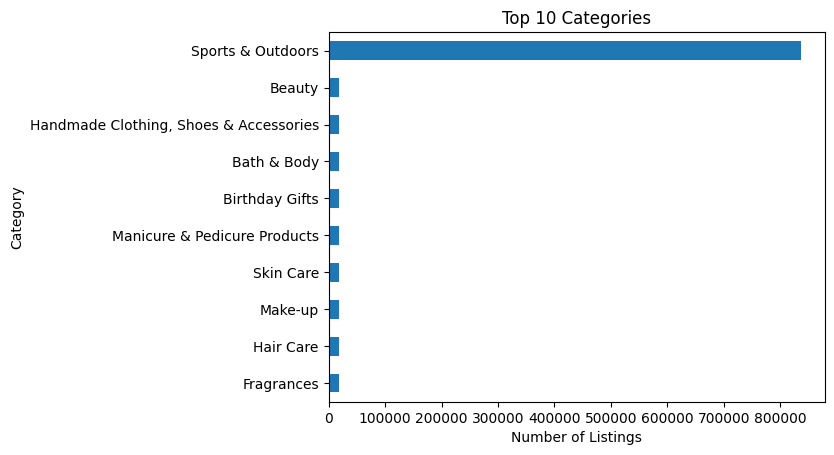

In [10]:
top10 = df['category'].value_counts().head(10)

top10.plot(kind='barh')
plt.title('Top 10 Categories')
plt.xlabel('Number of Listings')
plt.ylabel('Category')
plt.gca().invert_yaxis()
plt.show()

* As mentioned before, it is clear that Sports & Outdoors dominates the listings.

## Product Pricing

In [14]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print("mean_price:", mean_price, 
      "median_price:", median_price, 
      "mode_price:", mode_price)


mean_price: 89.24380943923661 median_price: 19.09 mode_price: 9.99


* Mean Price: The average price is 89.24 in Amazon Products.
* Median Price: Median price on 19.09 which shows us our central tendency the 50th percentile, this confirms expensive outliers in products.
* Mode Price: Mode price is 9.99 which shows the most common price in Amazon products.

## Dispersion

In [17]:
variance_price = df['price'].var()
std_price = df['price'].std()
price_range = df['price'].max() - df['price'].min()
iqr_price = df['price'].quantile(0.75) - df['price'].quantile(0.25)


print("variance_price:", variance_price,
      "std_price:", std_price,
      "price_range:", price_range,
      "iqr_price:", iqr_price)



variance_price: 119445.48532254901 std_price: 345.60886175349873 price_range: 100000.0 iqr_price: 36.0


* The product pricing shows extremely high variability, as indicated by a large variance and a standard deviation of approximately 345.
* This suggests that prices are widely spread out from the mean.

* The range of 100,000 is particularly significant, indicating the presence of very high-priced products compared to the majority of listings.

* However, the interquartile range of 36 tells a different story: most products are actually clustered within a relatively narrow price band.

* Although product prices vary widely, most items fall within a relatively small price range, with extreme outliers driving the overall dispersion.

## Product pricing Histogram

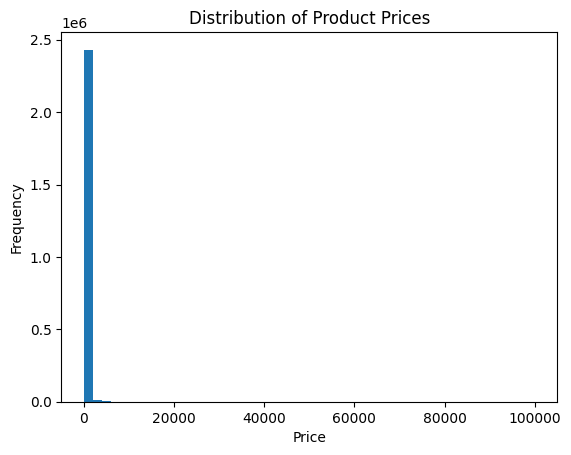

In [18]:
plt.hist(df['price'], bins=50)
plt.title('Distribution of Product Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

* As expected, the histogram comes completely messy due to price distribution.
* We can fix this by filtering or using a log scale to improve readability 

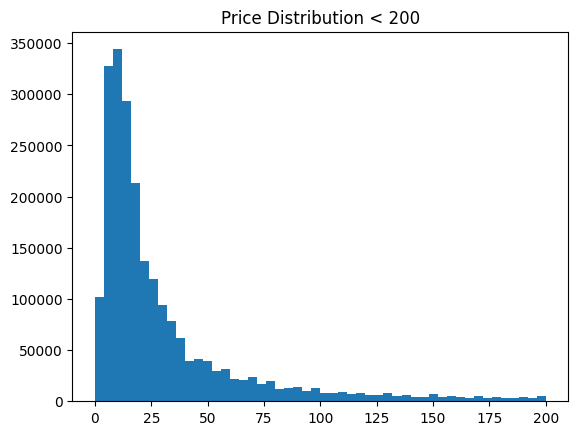

In [22]:
plt.hist(df[df['price'] < 200]['price'], bins=50)
plt.title('Price Distribution < 200')
plt.show()


* The histogram reveals a strong right-skewed distribution, where the majority of products are concentrated at lower price points, with frequencies rapidly declining as price increases.

* There is a clear peak in the £0–£25 range, indicating that most products on Amazon UK are positioned as low-cost or affordable items. 
* This suggests a pricing strategy focused on accessibility and high-volume sales.

* As prices increase beyond £25, the number of products decreases sharply, forming a long tail. This confirms that higher-priced items exist but are significantly less common.

## Price distribution BoxPlot

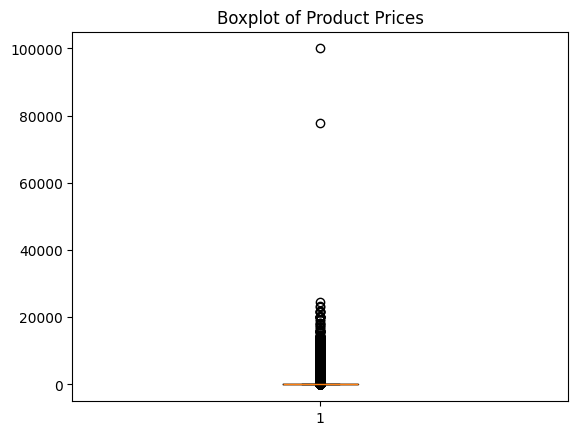

In [23]:
plt.boxplot(df['price'])
plt.title('Boxplot of Product Prices')
plt.show()

* The boxplot highlights numerous outliers on the pricing spectrum, confirming that a small number of products are priced significantly higher than the majority.

## Product Ratings


### Measure of centrality

In [24]:
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]

mean_rating, median_rating, mode_rating


(np.float64(2.152836472966066), np.float64(0.0), np.float64(0.0))

* Need to fix ratings

In [27]:
df_ratings = df[df['stars'] > 0]

# This filters out invalid ratings on the dataset

In [29]:
mean_rating = df_ratings['stars'].mean()
median_rating = df_ratings['stars'].median()
mode_rating = df_ratings['stars'].mode()[0]

print("mean_rating:", mean_rating,
      "median_rating:", median_rating,
      "mode_rating:", mode_rating)



mean_rating: 4.319160762226911 median_rating: 4.4 mode_rating: 4.5


* Ratings are generally good, with ~4.4 in man, median and mode.

* This concludes that most customers are satisfied with Amazon products

* Common Trend of ratings is 4.5

### Measure of dispersion

In [41]:
df_rated = df[df['stars'] > 0]

variance_rating = df_rated['stars'].var()
std_rating = df_rated['stars'].std()
iqr_rating = df_rated['stars'].quantile(0.75) - df_rated['stars'].quantile(0.25)

print(f"variance_rating: {variance_rating}")
print(f"std_rating: {std_rating}")
print(f"iqr_rating: {iqr_rating}")


variance_rating: 0.3083433752387284
std_rating: 0.5552867504620729
iqr_rating: 0.5


The ratings are highly consistent. The standard deviation is 0.555 and the interquartile range (IQR) is 0.5, meaning that the middle 50% of products differ by only half a star. This indicates that most products receive ratings clustered around the median (4.4), with few extreme low or high ratings. Therefore, there is not a wide variation in customer feedback — most customers rate products similarly, showing consistent satisfaction.

### Shape of Distribution

In [44]:
rating_skew = skew(df_rated['stars'])
rating_kurt = kurtosis(df_rated['stars'], fisher=False)  # Use fisher=False to get Pearson's kurtosis

print(f"Skewness: {rating_skew}")
print(f"Kurtosis: {rating_kurt}")

Skewness: -2.3795651817332555
Kurtosis: 12.781892609238655


* Ratings are strongly left-skewed and they strongly lean to higher values.

### Ratings Visualization

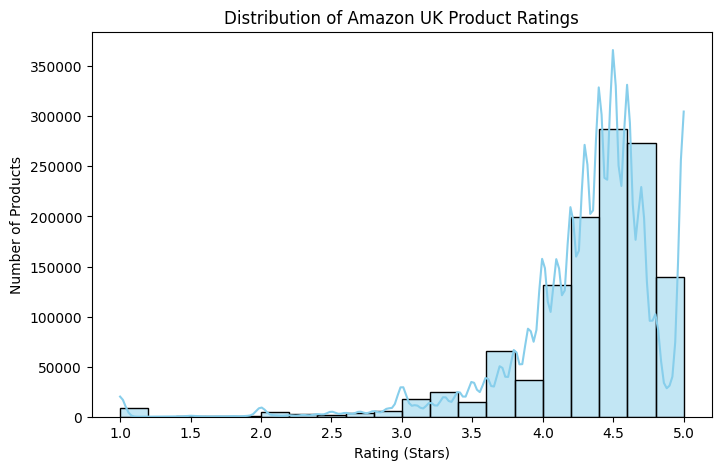

In [46]:
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(df_rated['stars'], bins=20, kde=True, color='skyblue')
plt.title("Distribution of Amazon UK Product Ratings")
plt.xlabel("Rating (Stars)")
plt.ylabel("Number of Products")
plt.show()


The histogram shows that the majority of Amazon UK products are rated highly, with the most common ratings around 4.5–4.7 stars. There is a sharp peak at these values, confirming the high concentration of positive ratings, while lower ratings are relatively rare.